In [ ]:
!pip install rasterio geopandas shapely fiona scipy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

DATA_DIR = "/content/drive/MyDrive/Ajmer_Rabi_RawData"
OUTPUT_DIR = "/content/drive/MyDrive/rabi_output/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("✅ Directories ready")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Directories ready


In [ ]:
import glob
from datetime import datetime

month_map = {
    "Jan":1,"Feb":2,"Mar":3,"Apr":4,"May":5,"Jun":6,
    "Jul":7,"Aug":8,"Sep":9,"Oct":10,"Nov":11,"Dec":12
}

def extract_date(filename):
    name = os.path.basename(filename).replace(".tif","")
    parts = name.split("_")
    return datetime(int(parts[2]), month_map[parts[3]], int(parts[4]))

tif_files = glob.glob(os.path.join(DATA_DIR, "**", "*.tif"), recursive=True)
tif_files = sorted(tif_files, key=extract_date)

print(f"📁 Total TIFF files found: {len(tif_files)}")
print("📅 First 5 files:")
for f in tif_files[:5]:
    print("  ", os.path.basename(f))

📁 Total TIFF files found: 14
📅 First 5 files:
   Ajmer_RAW_2024_Oct_01.tif
   Ajmer_RAW_2024_Oct_16.tif
   Ajmer_RAW_2024_Oct_31.tif
   Ajmer_RAW_2024_Nov_15.tif
   Ajmer_RAW_2024_Nov_30.tif


In [ ]:
import rasterio
import numpy as np

ndvi_stack = []
meta = None

for idx, file in enumerate(tif_files):
    with rasterio.open(file) as src:
        red = src.read(3).astype('float32')
        nir = src.read(7).astype('float32')

        denom = (nir + red)
        ndvi = np.where(denom == 0, np.nan, (nir - red) / denom)
        ndvi = np.clip(ndvi, -1, 1)

        ndvi_stack.append(ndvi)

        if meta is None:
            meta = src.meta

    print(f"✅ Processed {idx+1}/{len(tif_files)}")

ndvi_stack = np.stack(ndvi_stack, axis=0)

print("📊 NDVI stack shape:", ndvi_stack.shape)

✅ Processed 1/14
✅ Processed 2/14
✅ Processed 3/14
✅ Processed 4/14
✅ Processed 5/14
✅ Processed 6/14
✅ Processed 7/14
✅ Processed 8/14
✅ Processed 9/14
✅ Processed 10/14
✅ Processed 11/14
✅ Processed 12/14
✅ Processed 13/14
✅ Processed 14/14
📊 NDVI stack shape: (14, 532, 826)


In [ ]:
ndvi_max = np.nanmax(ndvi_stack, axis=0)
ndvi_min = np.nanmin(ndvi_stack, axis=0)
ndvi_amp = ndvi_max - ndvi_min
ndvi_std = np.nanstd(ndvi_stack, axis=0)

growth = np.diff(ndvi_stack, axis=0)
growth = np.nan_to_num(growth, nan=0)
growth_positive_count = np.sum(growth > 0, axis=0)

print("\n📊 NDVI Stats:")
print("NDVI max range:", np.nanmin(ndvi_max), np.nanmax(ndvi_max))
print("NDVI amplitude range:", np.nanmin(ndvi_amp), np.nanmax(ndvi_amp))
print("NDVI std range:", np.nanmin(ndvi_std), np.nanmax(ndvi_std))


📊 NDVI Stats:
NDVI max range: -0.040742647 0.7226443
NDVI amplitude range: 0.018407442 0.67184377
NDVI std range: 0.0049269604 0.24712223


/tmp/ipykernel_5074/3712315203.py:1: RuntimeWarning: All-NaN slice encountered
  ndvi_max = np.nanmax(ndvi_stack, axis=0)
/tmp/ipykernel_5074/3712315203.py:2: RuntimeWarning: All-NaN slice encountered
  ndvi_min = np.nanmin(ndvi_stack, axis=0)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [ ]:
agri_mask = (
    (ndvi_max > 0.45) &
    (ndvi_max < 0.65) &
    (ndvi_amp > 0.10) &
    (growth_positive_count >= 2) &
    (ndvi_std > 0.03)
)

agri_mask = agri_mask.astype('uint8')

print("\n🌾 Agriculture mask created")
print("Total agri pixels:", np.sum(agri_mask))


🌾 Agriculture mask created
Total agri pixels: 125211


In [ ]:
from scipy.ndimage import binary_closing, binary_opening

agri_mask = binary_closing(agri_mask, structure=np.ones((3,3)))
agri_mask = binary_opening(agri_mask, structure=np.ones((3,3)))

print("🧹 Morphological cleaning done")

🧹 Morphological cleaning done


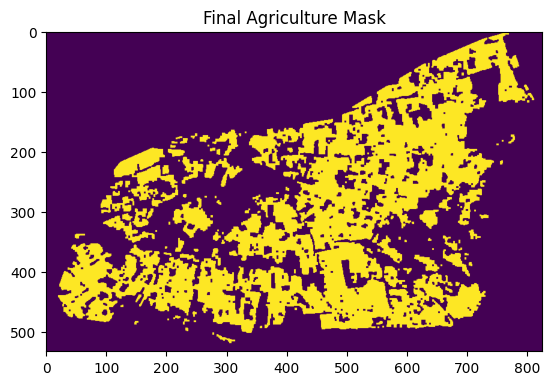

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(agri_mask)
plt.title("Final Agriculture Mask")
plt.show()

In [ ]:
meta.update({"count":1, "dtype":"uint8"})

mask_path = os.path.join(OUTPUT_DIR, "agri_mask.tif")

with rasterio.open(mask_path, "w", **meta) as dst:
    dst.write(agri_mask, 1)

print("💾 Saved raster mask:", mask_path)

💾 Saved raster mask: /content/drive/MyDrive/rabi_output/agri_mask.tif


In [ ]:
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape

results = []

with rasterio.open(mask_path) as src:
    image = src.read(1)
    transform = src.transform
    crs = src.crs

    for geom, value in shapes(image, transform=transform):
        if value == 1:
            results.append(shape(geom))

gdf = gpd.GeoDataFrame(geometry=results, crs=crs)

print("🗺️ Initial polygons:", len(gdf))

🗺️ Initial polygons: 122


In [ ]:
gdf_proj = gdf.to_crs(epsg=32643)

gdf_proj["area_m2"] = gdf_proj.geometry.area
gdf_proj["area_hectare"] = gdf_proj["area_m2"] / 10000
gdf_proj["area_acre"] = gdf_proj["area_m2"] / 4046.86

# Remove noise
gdf_proj = gdf_proj[gdf_proj["area_m2"] > 1500]

print("📉 Polygons after filtering:", len(gdf_proj))

📉 Polygons after filtering: 85


In [ ]:
total_crop_m2 = gdf_proj["area_m2"].sum()
total_crop_hectare = gdf_proj["area_hectare"].sum()
total_crop_acre = gdf_proj["area_acre"].sum()

print("\n🌾 TOTAL CROP AREA:")
print(f"Sq.m: {total_crop_m2:.2f}")
print(f"Hectare: {total_crop_hectare:.2f}")
print(f"Acre: {total_crop_acre:.2f}")


🌾 TOTAL CROP AREA:
Sq.m: 11956130.86
Hectare: 1195.61
Acre: 2954.42


In [ ]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import numpy as np

# -------------------------------
# STEP 1: Reproject raster to UTM
# -------------------------------
with rasterio.open(mask_path) as src:
    dst_crs = "EPSG:32643"  # UTM (meters)

    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds
    )

    kwargs = src.meta.copy()
    kwargs.update({
        'crs': dst_crs,
        'transform': transform,
        'width': width,
        'height': height
    })

    # Create empty array
    mask_reproj = np.zeros((height, width), dtype=np.uint8)

    reproject(
        source=rasterio.band(src, 1),
        destination=mask_reproj,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=transform,
        dst_crs=dst_crs,
        resampling=Resampling.nearest
    )

print("✅ Reprojection done")

✅ Reprojection done


In [ ]:
# Pixel size in meters
pixel_width = transform[0]
pixel_height = abs(transform[4])

pixel_area = pixel_width * pixel_height

# Total AOI pixels
total_pixels = mask_reproj.size

# Total area
total_area_m2 = total_pixels * pixel_area

total_area_hectare = total_area_m2 / 10000
total_area_acre = total_area_m2 / 4046.86

print("\n🌍 CORRECT TOTAL AOI AREA:")
print(f"Sq.m: {total_area_m2:.2f}")
print(f"Hectare: {total_area_hectare:.2f}")
print(f"Acre: {total_area_acre:.2f}")


🌍 CORRECT TOTAL AOI AREA:
Sq.m: 39296675.27
Hectare: 3929.67
Acre: 9710.41


In [ ]:
non_crop_m2 = total_area_m2 - total_crop_m2
non_crop_hectare = non_crop_m2 / 10000
non_crop_acre = non_crop_m2 / 4046.86

print("\n🚫 NON-CROP AREA:")
print(f"Hectare: {non_crop_hectare:.2f}")
print(f"Acre: {non_crop_acre:.2f}")


🚫 NON-CROP AREA:
Hectare: 2734.05
Acre: 6755.99


In [ ]:
fields_path = os.path.join(OUTPUT_DIR, "agriculture_fields.shp")
gdf_proj.to_file(fields_path)

print("💾 Saved field shapefile:", fields_path)

/tmp/ipykernel_5074/306460716.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf_proj.to_file(fields_path)
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'area_hectare' to 'area_hecta'
  ogr_write(


💾 Saved field shapefile: /content/drive/MyDrive/rabi_output/agriculture_fields.shp


In [ ]:
gdf_proj["class"] = 1
gdf_dissolved = gdf_proj.dissolve(by="class")

gdf_dissolved["geometry"] = gdf_dissolved.buffer(5).buffer(-5)
gdf_dissolved["geometry"] = gdf_dissolved.buffer(0)

gdf_final = gdf_dissolved.to_crs(epsg=4326)

boundary_path = os.path.join(OUTPUT_DIR, "agriculture_boundary.shp")
gdf_final.to_file(boundary_path)

print("💾 Saved boundary shapefile:", boundary_path)

💾 Saved boundary shapefile: /content/drive/MyDrive/rabi_output/agriculture_boundary.shp


/tmp/ipykernel_5074/1660883377.py:10: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf_final.to_file(boundary_path)
/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'area_hectare' to 'area_hecta'
  ogr_write(
